# 05 モデル診断: 引張強さの予測と重要特徴量

`processed_main` を使って、最初の目標変数 `S06020_060030`（引張強さ）を予測します。

このNotebookで確認すること:

- 重要特徴量を原料名に戻す
- 予測値と実測値を比較する
- 外れが大きい配合を見る
- 他の目標変数でもRandomForestを試す


In [1]:
import sys
from pathlib import Path

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(project_root / "src"))

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from plastech.modeling import random_forest_diagnostics, target_candidates

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 90)
plt.rcParams["font.family"] = ["Hiragino Sans", "Arial Unicode MS", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False


## 目標変数候補

最初に扱いやすい候補です。件数が多いほど、初回モデルの検証に使いやすくなります。


In [2]:
candidates = target_candidates()
display(candidates)


,column,name,detail,nonzero_count
0,S01010_010010,比重,比重_23ﾟC,5088
1,S06020_060030,引張強さ,JIS2 200mm/min,3930
2,S06060_060030,引張伸び,JIS2 200mm/min,3892
3,S06010_060030,100%モジュラス,JIS2 200mm/min,3838
4,S05010_050010_1,熱安定性,180ﾟC,3770
5,S13010_130010,脆化温度,JIS K6723,3392
6,S03010_030010,硬度 HDA,0s,3046


## 引張強さを目標変数にした診断

`S06020_060030` は `引張強さ_JIS2200mm/min` です。目標変数が `0` の行は未測定の可能性が高いため、学習から除外しています。


In [3]:
TARGET_COL = "S06020_060030"

diagnostics = random_forest_diagnostics(
    dataset_name="processed_main",
    target_col=TARGET_COL,
    n_estimators=300,
    random_state=42,
)

print(f"target: {diagnostics.prepared.target_col}")
print(f"rows used: {len(diagnostics.prepared.y)}")
print(f"features used: {len(diagnostics.prepared.feature_columns)}")
print({key: len(value) for key, value in diagnostics.prepared.dropped_columns.items()})

display(diagnostics.metrics)


target: S06020_060030
rows used: 3930
features used: 342
{'id_columns': 1, 'other_property_columns': 31, 'all_missing_columns': 0, 'constant_columns': 195}


,model,MAE,RMSE,R2
1,random_forest,1.694584,2.544944,0.769948
0,dummy_mean,4.226773,5.311520,-0.002089


## 重要特徴量を原料名に戻す

`可塑剤オイル類.29` のような機械的な列名を、`processed_main` の先頭2行に入っている分類名・原料名に戻して表示します。


In [4]:
top_importance = diagnostics.feature_importance.head(20)[
    ["column", "category", "label", "display_name", "importance"]
]
display(top_importance)


,column,category,label,display_name,importance
112,可塑剤オイル類.29,フタル酸エステル系,DOP,フタル酸エステル系 / DOP (可塑剤オイル類.29),0.218940
113,可塑剤オイル類.30,フタル酸エステル系,DINP,フタル酸エステル系 / DINP (可塑剤オイル類.30),0.170499
66,充填剤.2,未処理重質炭カル,NS400,未処理重質炭カル / NS400 (充填剤.2),0.100782
108,可塑剤オイル類.24,トリメリット酸系,TOTM,トリメリット酸系 / TOTM (可塑剤オイル類.24),0.036554
22,PVC.35,PVC700,TH700(BK),PVC700 / TH700(BK) (PVC.35),0.022865
114,可塑剤オイル類.31,フタル酸エステル系,DIDP,フタル酸エステル系 / DIDP (可塑剤オイル類.31),0.022746
12,PVC.23,PVC1300,TH1300(JG),PVC1300 / TH1300(JG) (PVC.23),0.022089
103,可塑剤オイル類.17,エポキシ化大豆油,S300K,エポキシ化大豆油 / S300K (可塑剤オイル類.17),0.021095
23,PVC.38,PVC800,TH800(DJ),PVC800 / TH800(DJ) (PVC.38),0.020413
10,PVC.15,PVC1000,TH1000(GW),PVC1000 / TH1000(GW) (PVC.15),0.019395


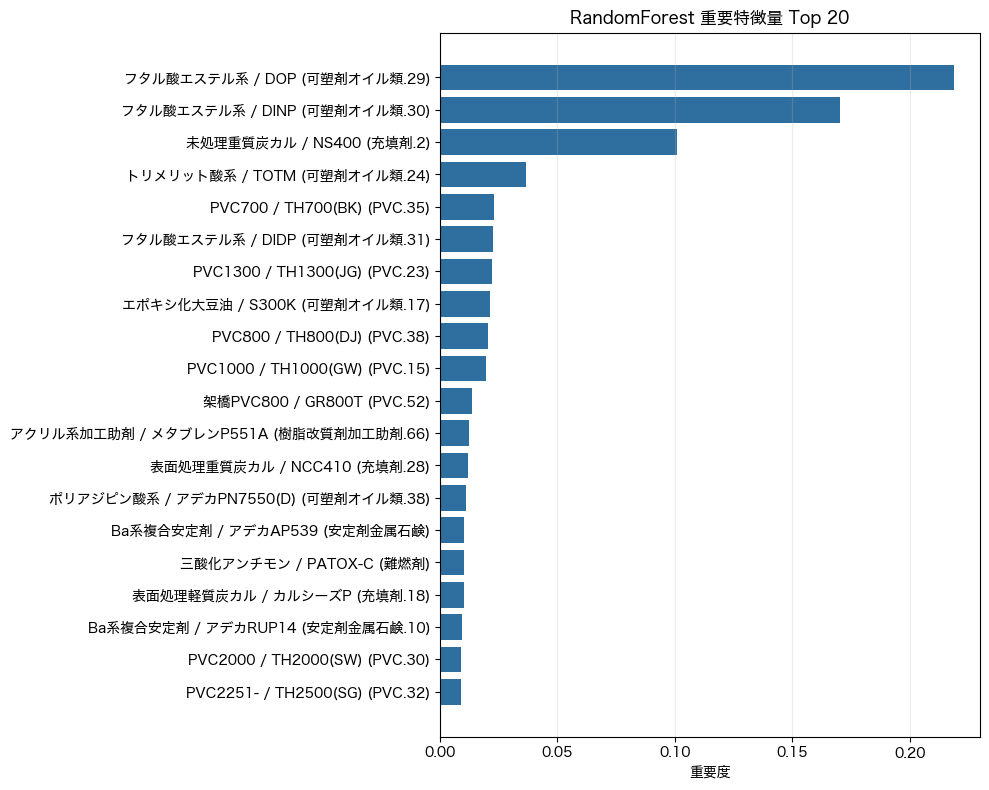

In [5]:
plot_df = top_importance.sort_values("importance")

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(plot_df["display_name"], plot_df["importance"], color="#2f6f9f")
ax.set_xlabel("重要度")
ax.set_title("RandomForest 重要特徴量 Top 20")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()


## 予測値 vs 実測値

左は実測値と予測値の散布図です。点が斜め線に近いほどよく当たっています。右は誤差の分布です。


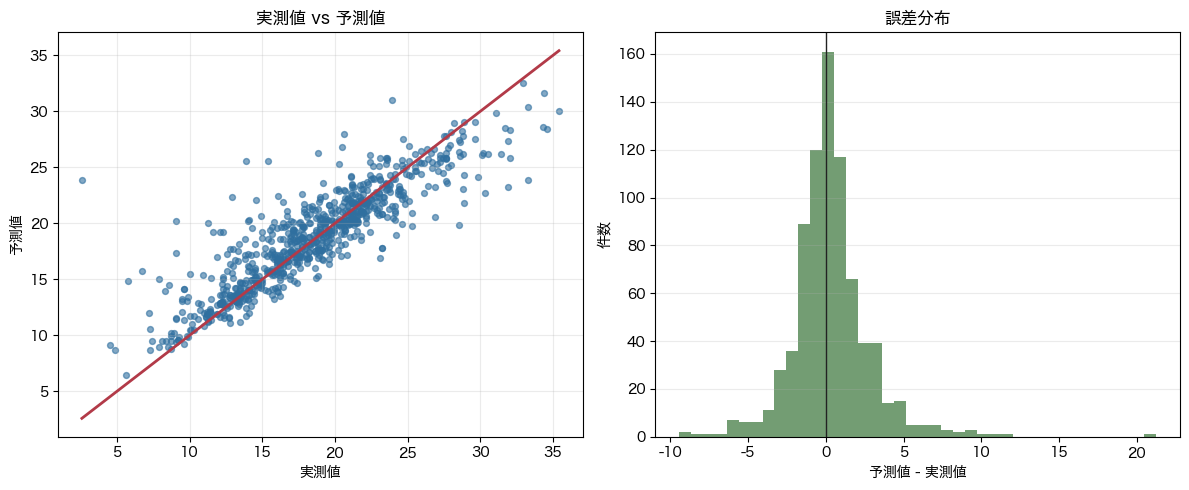

In [6]:
predictions = diagnostics.predictions.copy()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ax = axes[0]
ax.scatter(predictions["actual"], predictions["predicted"], s=18, alpha=0.6, color="#2f6f9f")
min_value = min(predictions["actual"].min(), predictions["predicted"].min())
max_value = max(predictions["actual"].max(), predictions["predicted"].max())
ax.plot([min_value, max_value], [min_value, max_value], color="#b23a48", linewidth=2)
ax.set_xlabel("実測値")
ax.set_ylabel("予測値")
ax.set_title("実測値 vs 予測値")
ax.grid(alpha=0.25)

ax = axes[1]
ax.hist(predictions["error"], bins=40, color="#5b8c5a", alpha=0.85)
ax.axvline(0, color="#222222", linewidth=1)
ax.set_xlabel("予測値 - 実測値")
ax.set_ylabel("件数")
ax.set_title("誤差分布")
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
plt.show()


## 外れが大きい配合

`abs_error` が大きい順に表示します。ここを見ると、どの配合でモデルが苦手かを確認できます。


In [7]:
display(predictions.head(20))


,row_id,actual,predicted,error,abs_error
783,CP0000000000993,2.6,23.849467,21.249467,21.249467
3004,CP0000000003854,13.9,25.564950,11.664950,11.664950
879,CP0000000001117,9.1,20.172983,11.072983,11.072983
4489,CP1000000007456,15.4,25.565000,10.165000,10.165000
2427,CP0000000003019,12.9,22.379222,9.479222,9.479222
1616,CP0000000002101,33.3,23.864917,-9.435083,9.435083
2761,CP0000000003370,6.7,15.751333,9.051333,9.051333
1445,CP0000000001903,5.8,14.849222,9.049222,9.049222
4522,CP1000000007609,11.3,20.071000,8.771000,8.771000
1262,CP0000000001618,28.5,19.826122,-8.673878,8.673878


,actual_range,count,mean_actual,mean_abs_error,max_abs_error
0,"(2.567, 6.7]",5,4.680000,7.932667,21.249467
1,"(6.7, 10.8]",46,9.121739,2.554855,11.072983
2,"(10.8, 14.9]",157,13.087261,1.629264,11.664950
3,"(14.9, 19.0]",224,17.102232,1.508804,10.165000
4,"(19.0, 23.1]",219,20.986301,1.220929,7.356667
5,"(23.1, 27.2]",86,24.748837,1.796078,7.110533
6,"(27.2, 31.3]",36,28.583333,2.636681,8.673878
7,"(31.3, 35.4]",13,33.007692,4.940214,9.435083


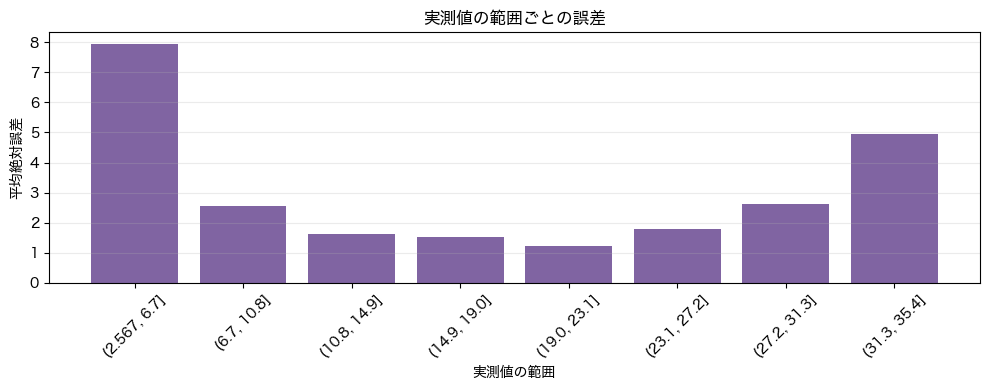

In [8]:
error_by_range = predictions.copy()
error_by_range["actual_range"] = pd.cut(error_by_range["actual"], bins=8)
error_summary = (
    error_by_range.groupby("actual_range", observed=True)
    .agg(
        count=("abs_error", "size"),
        mean_actual=("actual", "mean"),
        mean_abs_error=("abs_error", "mean"),
        max_abs_error=("abs_error", "max"),
    )
    .reset_index()
)

display(error_summary)

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(error_summary["actual_range"].astype(str), error_summary["mean_abs_error"], color="#8064a2")
ax.set_xlabel("実測値の範囲")
ax.set_ylabel("平均絶対誤差")
ax.set_title("実測値の範囲ごとの誤差")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()


## 他の目標変数でも試す

同じ前処理・同じRandomForestで複数の物性を比較します。ここでは件数が比較的多い候補を対象にしています。


In [9]:
comparison_targets = [
    "S06020_060030",  # 引張強さ
    "S06060_060030",  # 引張伸び
    "S06010_060030",  # 100%モジュラス
    "S03010_030010",  # 硬度 HDA
    "S13010_130010",  # 脆化温度
]

candidate_names = candidates.set_index("column")[["name", "detail"]]
comparison_rows = []

for target in comparison_targets:
    result = random_forest_diagnostics(
        dataset_name="processed_main",
        target_col=target,
        n_estimators=200,
        random_state=42,
    )
    row = result.metrics[result.metrics["model"] == "random_forest"].iloc[0].to_dict()
    row["target_col"] = target
    row["target_name"] = candidate_names.loc[target, "name"] if target in candidate_names.index else target
    row["target_detail"] = candidate_names.loc[target, "detail"] if target in candidate_names.index else ""
    row["rows"] = len(result.prepared.y)
    row["features"] = len(result.prepared.feature_columns)
    comparison_rows.append(row)

comparison = pd.DataFrame(comparison_rows)[
    ["target_col", "target_name", "target_detail", "rows", "features", "MAE", "RMSE", "R2"]
].sort_values("R2", ascending=False)

display(comparison)


,target_col,target_name,target_detail,rows,features,MAE,RMSE,R2
3,S03010_030010,硬度 HDA,0s,3046,343,2.950724,4.675562,0.864022
2,S06010_060030,100%モジュラス,JIS2 200mm/min,3838,338,0.976199,1.594787,0.861089
4,S13010_130010,脆化温度,JIS K6723,3392,332,3.228067,4.462087,0.808034
0,S06020_060030,引張強さ,JIS2 200mm/min,3930,342,1.702129,2.557386,0.767694
1,S06060_060030,引張伸び,JIS2 200mm/min,3892,338,23.237182,38.406606,0.672969


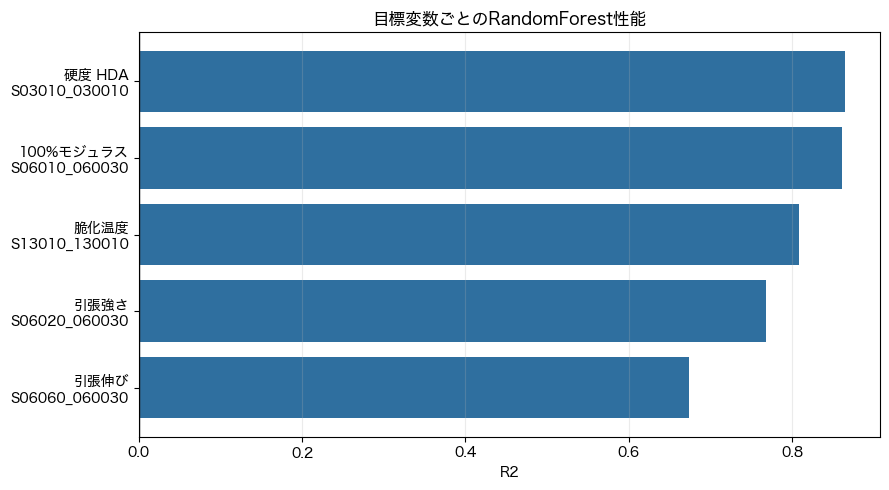

In [10]:
plot_comparison = comparison.sort_values("R2")
labels = plot_comparison["target_name"] + "\n" + plot_comparison["target_col"]

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(labels, plot_comparison["R2"], color="#2f6f9f")
ax.set_xlabel("R2")
ax.set_title("目標変数ごとのRandomForest性能")
ax.axvline(0, color="#222222", linewidth=1)
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()


## 次に見るポイント

- 重要特徴量の上位原料が、材料知識として妥当か確認する
- 外れが大きい配合に共通する原料・配合系を確認する
- `R2` が高い物性から、順方向モデルを安定化する
- その後、目標物性に近い配合を探索する逆解析へ進む
